# 01 — Análise Exploratória: Adult Income

Bem-vindo ao **ML-02**! No ML-01, previmos um **número** (o preço das casas): um problema de **regressão**. Agora vamos prever uma **categoria**: se uma pessoa ganha **mais ou menos de US\$ 50 mil por ano**. Isso é um problema de **classificação**.

Antes de treinar qualquer modelo, vamos **conhecer os dados**, como fizemos no notebook 01 do ML-01. Desta vez, os dados são bem mais "reais" e trazem desafios novos:

- Colunas de **texto** (categorias), e não só números
- **Valores ausentes**
- Classes **desbalanceadas**
- Questões de **justiça** (*fairness*): o que um modelo aprende sobre sexo e raça?

> Lembrete: execute as células em ordem com `Shift + Enter`. Linhas que começam com `#` são comentários.

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# fetch_openml baixa datasets do OpenML (openml.org), um grande repositório público de dados.
# O Adult não vem dentro do scikit-learn como o California Housing; ele é baixado na primeira vez
# e fica guardado no computador para as próximas.
from sklearn.datasets import fetch_openml

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 20)   # mostra até 20 colunas sem esconder nenhuma
plt.rcParams["figure.dpi"] = 100

# version=2 é a versão "oficial" do Adult no OpenML. as_frame=True devolve uma tabela do pandas.
adult = fetch_openml("adult", version=2, as_frame=True)
df = adult.frame
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


Cada linha é **uma pessoa** que respondeu a uma pesquisa do **censo americano de 1994**. O que cada coluna significa:

| Coluna | Significado | Tipo |
|---|---|---|
| `age` | Idade | número |
| `workclass` | Tipo de empregador (privado, governo, autônomo...) | categoria |
| `fnlwgt` | Peso amostral do censo (explicado na seção 6) | número |
| `education` | Escolaridade (nome) | categoria |
| `education-num` | Escolaridade (código numérico, de 1 a 16) | número |
| `marital-status` | Estado civil | categoria |
| `occupation` | Profissão | categoria |
| `relationship` | Papel na família (marido, esposa, filho...) | categoria |
| `race` | Raça | categoria |
| `sex` | Sexo | categoria |
| `capital-gain` | Ganho com investimentos no ano (US\$) | número |
| `capital-loss` | Perda com investimentos no ano (US\$) | número |
| `hours-per-week` | Horas trabalhadas por semana | número |
| `native-country` | País de origem | categoria |
| `class` | **Alvo**: renda anual `<=50K` ou `>50K` | categoria |

## 2. Estrutura: tamanho e tipos de coluna

In [2]:
print("Formato:", df.shape)   # (linhas, colunas)

# .dtypes mostra o tipo de cada coluna:
#   int64    -> número inteiro
#   category -> categoria: um texto que se repete entre poucas opções (ex.: "Male"/"Female")
df.dtypes

Formato: (48842, 15)


age                  int64
workclass         category
fnlwgt               int64
education         category
education-num        int64
marital-status    category
occupation        category
relationship      category
race              category
sex               category
capital-gain         int64
capital-loss         int64
hours-per-week       int64
native-country    category
class             category
dtype: object

## 🎓 Conceito: atributos numéricos × categóricos

- **Numéricos** são quantidades: faz sentido somar, tirar média, dizer que um é "maior" que outro. Exemplos: idade, horas trabalhadas.
- **Categóricos** são **rótulos**: "Private", "Married", "Sales". Não faz sentido calcular a média de profissões.

Isso importa porque **modelos de ML só fazem contas com números**. No ML-01 todas as colunas já eram numéricas. Aqui, 8 das 14 colunas de entrada são texto. No notebook 03 vamos aprender a **transformar categorias em números** sem inventar uma ordem que não existe (*one-hot encoding*).

Algumas categorias **têm** uma ordem natural, como a escolaridade (fundamental < médio < superior). Essas se chamam **ordinais**. As que não têm ordem, como profissão e país, se chamam **nominais**.

In [3]:
# select_dtypes separa as colunas pelo tipo.
numericas = df.select_dtypes("number").columns.tolist()          # .tolist() transforma em lista do Python
categoricas = df.select_dtypes("category").columns.drop("class").tolist()   # sem o alvo

print(f"{len(numericas)} numéricas:  {numericas}")
print(f"{len(categoricas)} categóricas: {categoricas}")

6 numéricas:  ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
8 categóricas: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


**Conclusão:** temos **48.842 pessoas** e 14 colunas de entrada: **6 numéricas** e **8 categóricas**, além do alvo `class`. Mais da metade das informações está em texto, e precisaremos transformá-las antes de treinar modelos.

## 3. O alvo: quantas pessoas ganham mais de 50 mil?

       pessoas  proporção
class                    
<=50K    37155      0.761
>50K     11687      0.239


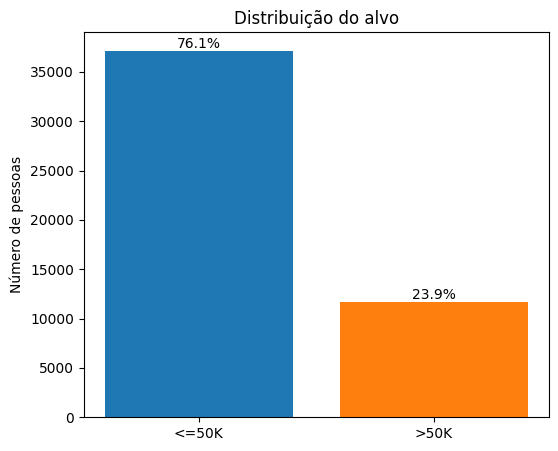

In [4]:
# value_counts conta quantas vezes cada valor aparece; normalize=True devolve proporções.
contagem = df["class"].value_counts()
proporcao = df["class"].value_counts(normalize=True)

print(pd.DataFrame({"pessoas": contagem, "proporção": proporcao.round(3)}))

fig, ax = plt.subplots(figsize=(6, 5.0))
ax.bar(contagem.index.astype(str), contagem.values, color=["tab:blue", "tab:orange"])
ax.set_ylabel("Número de pessoas")
ax.set_title("Distribuição do alvo")

for i, (n, p) in enumerate(zip(contagem.values, proporcao.values)):
    ax.text(i, n, f"{p:.1%}", ha="center", va="bottom")   # escreve a porcentagem em cima da barra

plt.show()

## 🎓 Conceito: classes desbalanceadas

Na classificação, cada valor possível do alvo é uma **classe**. Aqui temos duas: `<=50K` e `>50K`, ou seja, uma classificação **binária**.

As classes estão **desbalanceadas**: **76%** das pessoas ganham até 50 mil, e só **24%** ganham mais. Isso cria uma armadilha.

Imagine um "modelo" que **sempre** responde `<=50K`, para qualquer pessoa. Ele acerta **76%** das vezes, sem ter aprendido absolutamente nada! Esse é o equivalente do baseline "sempre prever a média" do ML-01.

Por isso, em classificação, "acertar 76%" pode ser um resultado **péssimo**. No notebook 02 vamos ver que a **acurácia** (porcentagem de acertos) engana, e no notebook 04 vamos aprender métricas que não caem nessa armadilha.

Para facilitar as análises, vamos criar uma coluna numérica: **1** para quem ganha mais de 50 mil e **0** para os demais. Assim, a **média** dessa coluna em um grupo é a **taxa de renda alta** daquele grupo.

In [5]:
# (df["class"] == ">50K") gera True/False; .astype(int) transforma em 1/0.
df["renda_alta"] = (df["class"] == ">50K").astype(int)

taxa_geral = df["renda_alta"].mean()   # média de 0s e 1s = proporção de 1s
print(f"Taxa geral de renda alta: {taxa_geral:.1%}")

Taxa geral de renda alta: 23.9%


**Conclusão:** **23,9%** das pessoas ganham mais de 50 mil. Esse número vai servir de **referência** em todo o notebook: um grupo com taxa bem acima de 23,9% tem mais renda alta do que a média, e um grupo abaixo tem menos.

## 4. Valores ausentes

In [6]:
# isna() marca as células vazias; sum() conta por coluna.
ausentes = df.isna().sum()
ausentes = ausentes[ausentes > 0]   # filtra só as colunas com algum valor ausente

pd.DataFrame({"ausentes": ausentes, "% das linhas": (ausentes / len(df) * 100).round(1)})

,ausentes,% das linhas
workclass,2799,5.7
occupation,2809,5.8
native-country,857,1.8


## 🎓 Conceito: valores ausentes

No arquivo original do censo, os valores desconhecidos aparecem como um ponto de interrogação ("?"). O OpenML já os converteu para **NaN** (*Not a Number*), o marcador de "vazio" do pandas.

Antes de decidir o que fazer com eles, vale perguntar **por que** estão faltando. A ausência pode ser aleatória (alguém esqueceu de responder) ou pode **ter um significado**. Por exemplo, alguém sem emprego não tem profissão para informar.

In [7]:
sem_workclass = df["workclass"].isna()
sem_occupation = df["occupation"].isna()

# & é o "E" lógico entre dois filtros: as duas condições precisam ser verdadeiras.
print("Sem workclass E sem occupation:       ", (sem_workclass & sem_occupation).sum())
print("Sem occupation, mas COM workclass:    ", (sem_occupation & ~sem_workclass).sum())
print("  ... e qual é a workclass delas?     ", df.loc[sem_occupation & ~sem_workclass, "workclass"].unique().tolist())

# A taxa de renda alta muda quando a profissão está ausente?
print(f"\nTaxa de renda alta COM profissão informada: {df.loc[~sem_occupation, 'renda_alta'].mean():.1%}")
print(f"Taxa de renda alta SEM profissão informada: {df.loc[sem_occupation, 'renda_alta'].mean():.1%}")

Sem workclass E sem occupation:        2799
Sem occupation, mas COM workclass:     10
  ... e qual é a workclass delas?      ['Never-worked']

Taxa de renda alta COM profissão informada: 24.8%
Taxa de renda alta SEM profissão informada: 9.4%


**Conclusão:**
- Só 3 colunas têm valores ausentes, todas **categóricas**: `workclass` e `occupation` (~5,7% das linhas cada) e `native-country` (~1,8%).
- `workclass` e `occupation` **faltam juntas**: as 2.799 pessoas sem tipo de empregador também não têm profissão. As outras 10 sem profissão são justamente as que **nunca trabalharam** (`Never-worked`). Faz todo sentido!
- **A ausência é informativa:** entre quem não informou a profissão, só **9,4%** ganham mais de 50 mil, contra 24,8% dos demais. Provavelmente muitas dessas pessoas estão desempregadas ou fora do mercado de trabalho.

Por isso, **apagar** essas linhas seria um erro: perderíamos informação útil e deixaríamos o modelo incapaz de lidar com casos assim no futuro. No notebook 03 vamos tratá-las criando uma categoria própria, como "Desconhecido", para que o modelo possa aprender com a própria ausência.

## 5. Linhas duplicadas

In [8]:
duplicadas = df.duplicated()   # True para cada linha idêntica a uma linha anterior
print(f"Linhas duplicadas: {duplicadas.sum()} de {len(df)} ({duplicadas.mean():.2%})")

Linhas duplicadas: 52 de 48842 (0.11%)


**Conclusão:** há **52 linhas** idênticas a outras (0,1%). Num censo com dezenas de milhões de pessoas, é perfeitamente possível que duas pessoas diferentes tenham exatamente as mesmas respostas, ainda mais porque o `fnlwgt` agrupa pessoas parecidas. Como são poucas e provavelmente legítimas, vamos **mantê-las**.

## 6. Distribuição das variáveis numéricas

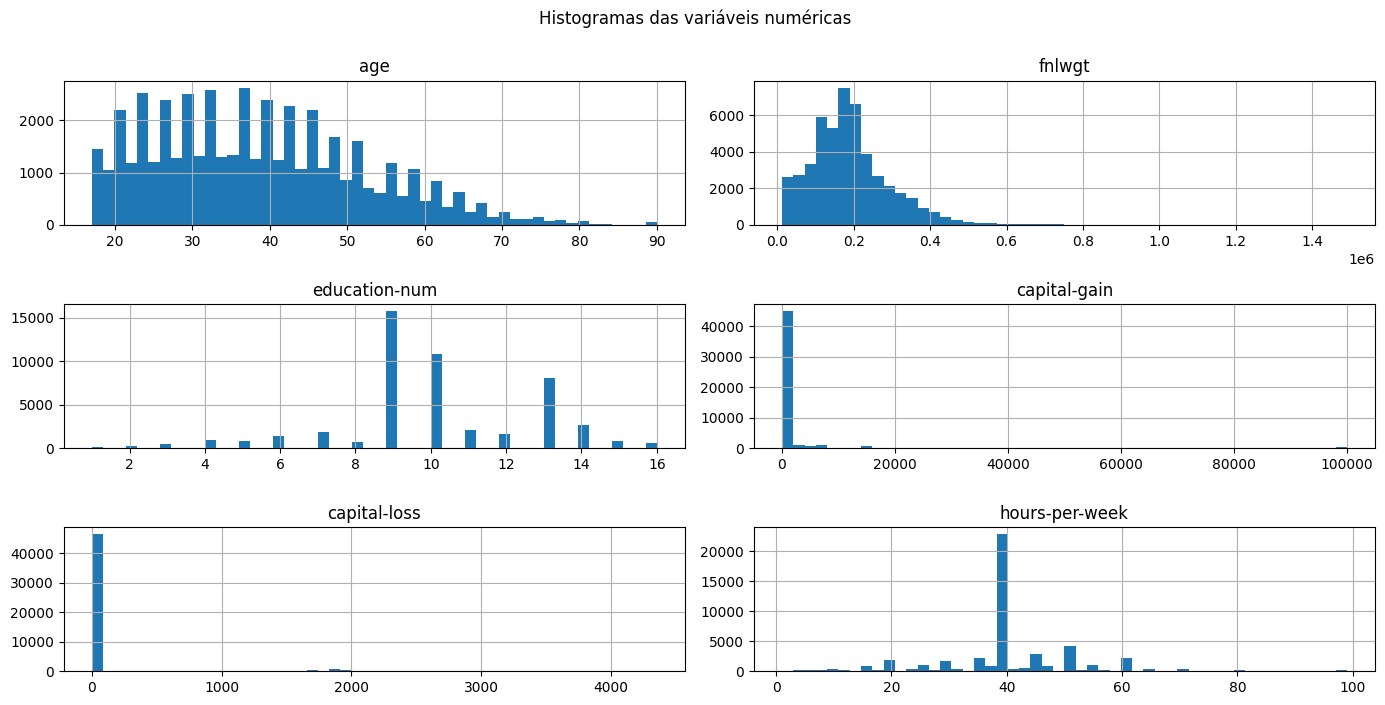

,count,mean,std,min,25%,50%,75%,max
age,"48,842.0",38.6,13.7,17.0,28.0,37.0,48.0,90.0
fnlwgt,"48,842.0","189,664.1","105,604.0","12,285.0","117,550.5","178,144.5","237,642.0","1,490,400.0"
education-num,"48,842.0",10.1,2.6,1.0,9.0,10.0,12.0,16.0
capital-gain,"48,842.0","1,079.1","7,452.0",0.0,0.0,0.0,0.0,"99,999.0"
capital-loss,"48,842.0",87.5,403.0,0.0,0.0,0.0,0.0,"4,356.0"
hours-per-week,"48,842.0",40.4,12.4,1.0,40.0,40.0,45.0,99.0


In [9]:
df[numericas].hist(bins=50, figsize=(14, 7))
plt.suptitle("Histogramas das variáveis numéricas", y=1.0)
plt.tight_layout()
plt.show()

# option_context muda uma configuração do pandas só dentro do bloco "with":
# aqui, mostra os números com 1 casa decimal e separador de milhar, evitando a notação científica.
# display() exibe uma tabela no meio da célula (normalmente só a última linha é exibida).
with pd.option_context("display.float_format", "{:,.1f}".format):
    display(df[numericas].describe().T)

In [10]:
# Olhando mais de perto as colunas de investimentos e de horas:
print(f"capital-gain igual a zero:   {(df['capital-gain'] == 0).mean():.1%}")
print(f"capital-loss igual a zero:   {(df['capital-loss'] == 0).mean():.1%}")
print(f"capital-gain igual a 99999:  {(df['capital-gain'] == 99999).sum()} pessoas")
print(f"Exatamente 40 horas/semana:  {(df['hours-per-week'] == 40).mean():.1%}")

capital-gain igual a zero:   91.7%
capital-loss igual a zero:   95.3%
capital-gain igual a 99999:  244 pessoas
Exatamente 40 horas/semana:  46.7%


**Conclusão:**
- **`age`:** de 17 a 90 anos, concentrada entre 28 e 48 anos (o "meio" de 50% das pessoas).
- **`hours-per-week`:** um pico enorme em **40 horas**, a jornada padrão (47% das pessoas).
- **`capital-gain` e `capital-loss`:** quase todo mundo tem **zero** (92% e 95%). Investimentos são coisa de uma minoria. Além disso, **244 pessoas** têm ganho de exatamente **99.999**, o maior número de 5 dígitos: provavelmente um **limite** do formulário, parecido com o teto em 5,0 do California Housing.
- **`education-num`:** é um código de 1 a 16 para a escolaridade (seção 9).
- **`fnlwgt`:** é o **peso amostral** do censo, ou seja, quantas pessoas da população cada entrevistado "representa". Ele é usado por estatísticos para estimar totais do país, mas **não é uma característica da pessoa**. Vamos confirmar na seção 10 que ele não ajuda a prever a renda.

## 7. Variáveis numéricas × renda

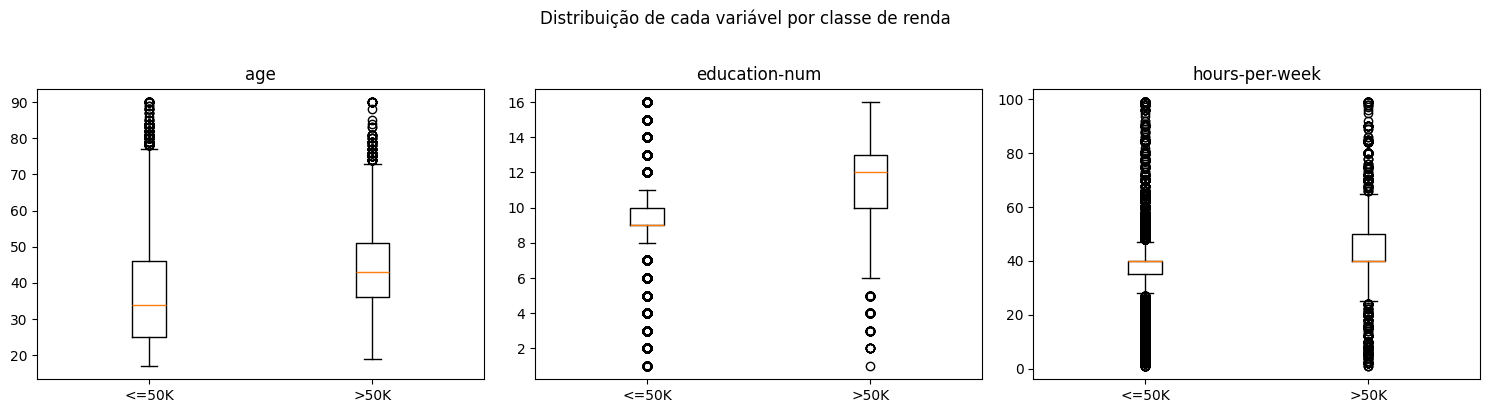

,age,education-num,hours-per-week
class,,,
<=50K,34.0,9.0,40.0
>50K,43.0,12.0,40.0


In [11]:
colunas_analise = ["age", "education-num", "hours-per-week"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, coluna in zip(axes, colunas_analise):
    # Separa os valores da coluna em dois grupos, um para cada classe.
    grupos = [df.loc[df["class"] == classe, coluna] for classe in ["<=50K", ">50K"]]
    ax.boxplot(grupos)
    ax.set_xticks([1, 2], ["<=50K", ">50K"])
    ax.set_title(coluna)
plt.suptitle("Distribuição de cada variável por classe de renda", y=1.02)
plt.tight_layout()
plt.show()

# observed=True: considera só as categorias que de fato aparecem (detalhe do tipo "category" do pandas).
df.groupby("class", observed=True)[colunas_analise].median()

**Conclusão:** quem ganha mais de 50 mil tende a ser **mais velho** (mediana de 43 contra 34 anos) e **mais escolarizado** (mediana 12 contra 9 no código de escolaridade). Nas **horas**, as medianas são iguais (40), mas a caixa da renda alta é deslocada para cima: muitas pessoas de renda alta trabalham **mais** de 40 horas.

Vamos ver como a renda muda ao longo da idade:

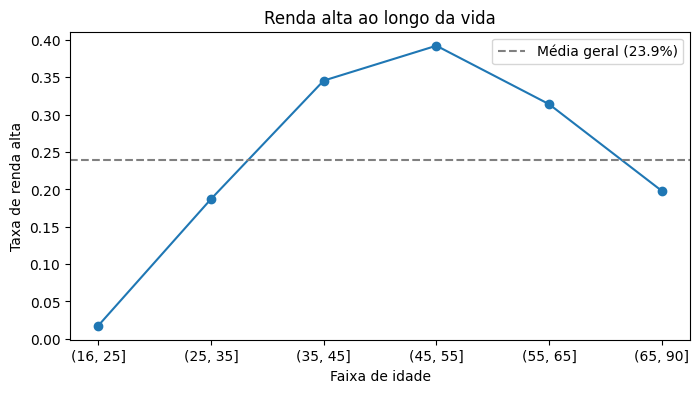

age
(16, 25]    0.018
(25, 35]    0.187
(35, 45]    0.346
(45, 55]    0.392
(55, 65]    0.314
(65, 90]    0.198
Name: renda_alta, dtype: float64

In [12]:
# pd.cut divide as idades em faixas; depois calculamos a taxa de renda alta em cada faixa.
faixas_idade = pd.cut(df["age"], bins=[16, 25, 35, 45, 55, 65, 90])
taxa_por_idade = df.groupby(faixas_idade, observed=True)["renda_alta"].mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(taxa_por_idade.index.astype(str), taxa_por_idade.values, marker="o")
ax.axhline(taxa_geral, color="gray", linestyle="--", label=f"Média geral ({taxa_geral:.1%})")
ax.set_xlabel("Faixa de idade")
ax.set_ylabel("Taxa de renda alta")
ax.set_title("Renda alta ao longo da vida")
ax.legend()
plt.show()

taxa_por_idade.round(3)

**Conclusão:** a renda alta forma uma **curva em "U" invertido**. É raríssima até os 25 anos (1,8%), cresce até o pico entre **45 e 55 anos** (39%) e volta a cair depois dos 55, com a aposentadoria.

⚠️ Essa relação **não é linear**: não dá para dizer "quanto mais velho, mais renda". Lembre do ML-01: modelos lineares têm dificuldade com curvas assim, e as árvores lidam com elas naturalmente.

## 🎓 Conceito: taxa da classe por categoria

Para colunas **numéricas**, usamos correlação e gráficos de dispersão. Para colunas **categóricas**, a ferramenta mais simples e poderosa é a **taxa da classe por categoria**: para cada valor da coluna, qual porcentagem das pessoas ganha mais de 50 mil?

Se as taxas variam muito entre as categorias, a coluna é **informativa** para prever a renda. Se todas ficam perto da média geral (23,9%), ela ajuda pouco.

⚠️ Cuidado com **categorias raras**: uma taxa calculada com 10 pessoas é muito menos confiável que uma calculada com 10 mil. Por isso vamos sempre mostrar a contagem junto.

## 8. Variáveis categóricas × renda

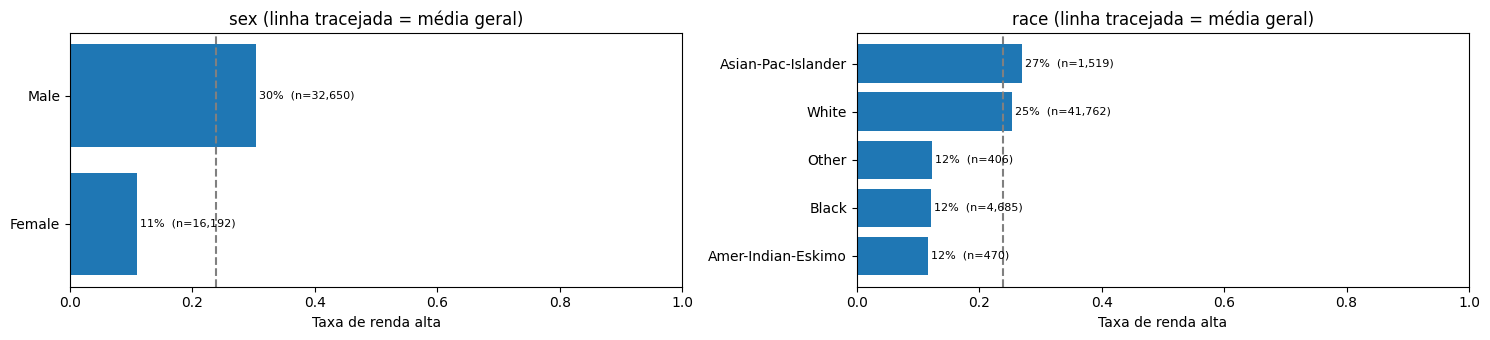

In [13]:
def taxa_por_categoria(coluna, ordem=None, ax=None):
    """Gráfico de barras com a taxa de renda alta de cada categoria de uma coluna."""
    tabela = df.groupby(coluna, observed=True)["renda_alta"].agg(["mean", "count"])
    tabela.columns = ["taxa de renda alta", "pessoas"]
    # Ordena pela ordem pedida (ex.: escolaridade) ou, se não houver, pela taxa.
    tabela = tabela.loc[ordem] if ordem is not None else tabela.sort_values("taxa de renda alta")

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 0.35 * len(tabela) + 1))
    ax.barh(tabela.index.astype(str), tabela["taxa de renda alta"])
    ax.axvline(taxa_geral, color="gray", linestyle="--")
    ax.set_title(f"{coluna} (linha tracejada = média geral)")
    ax.set_xlabel("Taxa de renda alta")
    for i, (taxa, n) in enumerate(zip(tabela["taxa de renda alta"], tabela["pessoas"])):
        ax.text(taxa + 0.005, i, f"{taxa:.0%}  (n={n:,})", va="center", fontsize=8)
    ax.set_xlim(0, 1)
    return tabela


fig, axes = plt.subplots(1, 2, figsize=(15, 3.5))
taxa_por_categoria("sex", ax=axes[0])
taxa_por_categoria("race", ax=axes[1])
plt.tight_layout()
plt.show()

**Conclusão:**
- **Sexo:** **30%** dos homens ganham mais de 50 mil, contra apenas **11%** das mulheres, quase 3 vezes menos.
- **Raça:** brancos (25%) e asiáticos (27%) ficam perto ou acima da média; negros (12%), indígenas (12%) e "outros" (12%) ficam bem abaixo.

São diferenças grandes, e elas **refletem desigualdades reais** da sociedade americana de 1994. Um modelo treinado com esses dados vai **aprender** esses padrões. Voltaremos a isso na seção 11 e, com mais profundidade, no último notebook.

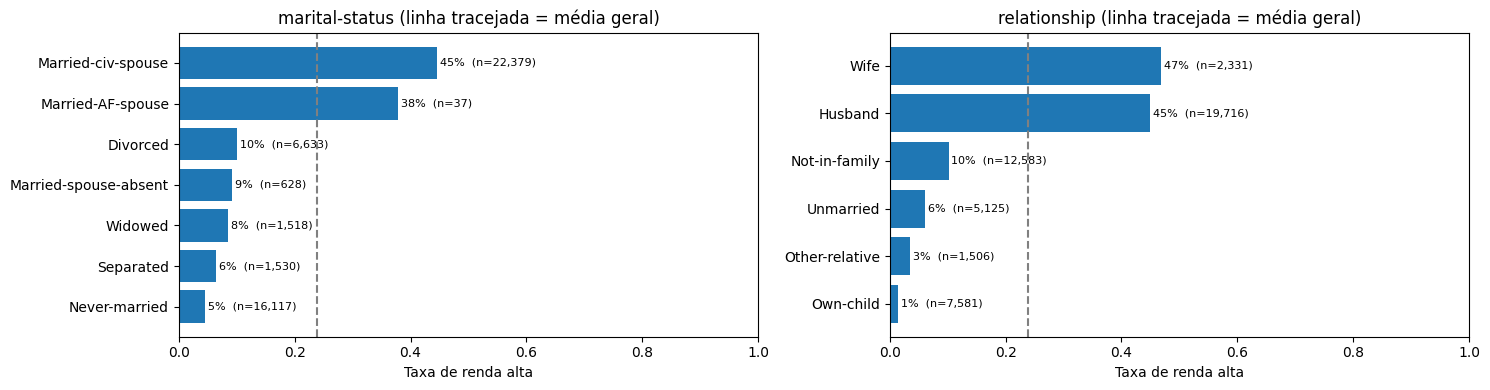

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
taxa_por_categoria("marital-status", ax=axes[0])
taxa_por_categoria("relationship", ax=axes[1])
plt.tight_layout()
plt.show()

**Conclusão:** o **estado civil** é uma das colunas mais informativas:
- **Casados** (`Married-civ-spouse`) têm **45%** de renda alta, quase o dobro da média.
- **Nunca casados** têm só **4,5%**. Muitos são jovens (lembre da curva de idade), então parte desse efeito vem da idade.
- Em `relationship`, maridos (45%) e esposas (47%) lideram, e filhos (`Own-child`) têm apenas 1,5%.

⚠️ Uma observação importante: no censo de 1994, a renda de **casais** muitas vezes é declarada como a **renda do domicílio**. Isso pode explicar parte da taxa alta dos casados. **Correlação não é causa**: casar não aumenta o salário!

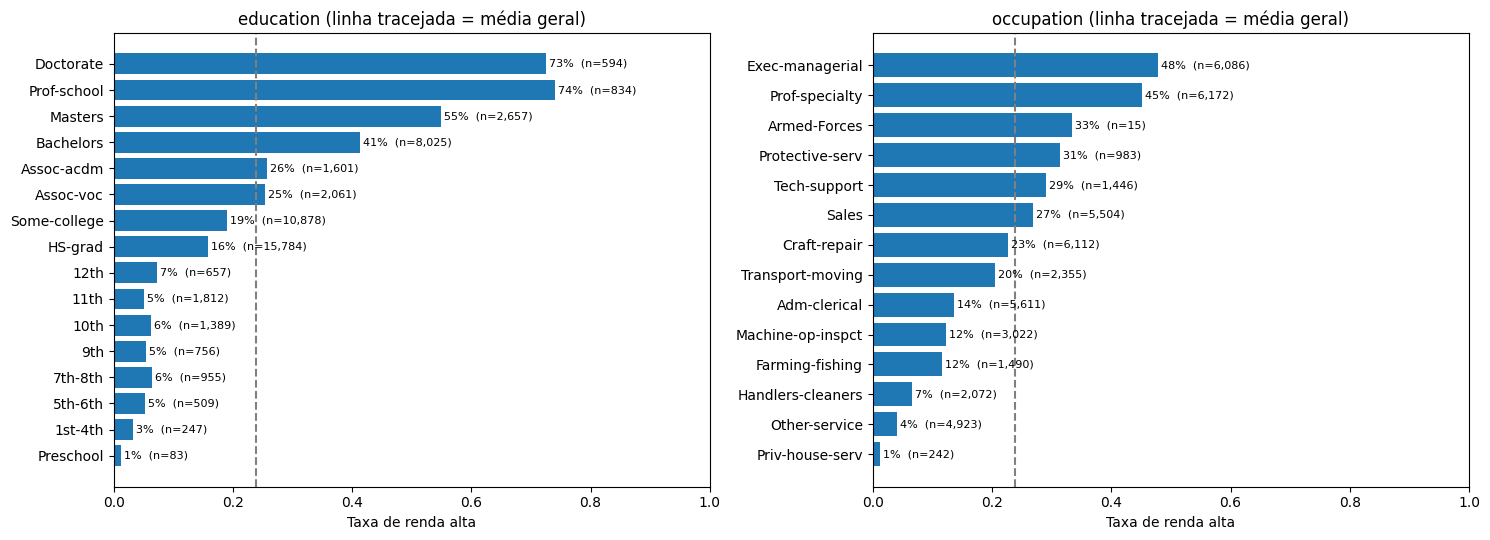

In [15]:
# A escolaridade tem uma ordem natural: vamos usar o código education-num para ordenar as barras.
ordem_escolaridade = (
    df.groupby("education", observed=True)["education-num"].first()   # o código de cada nível
    .sort_values().index                                              # níveis do menor para o maior
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
taxa_por_categoria("education", ordem=ordem_escolaridade, ax=axes[0])
taxa_por_categoria("occupation", ax=axes[1])
plt.tight_layout()
plt.show()

**Conclusão:**
- **Escolaridade:** a taxa cresce quase sempre junto com o nível. Ela é baixíssima sem ensino médio (de 1% a 7%), sobe para 16% com ensino médio (`HS-grad`), 41% com graduação (`Bachelors`), 55% com mestrado e mais de **70%** com doutorado ou formação profissional (`Prof-school`: medicina, direito).
- **Profissão:** gerentes (`Exec-managerial`, 48%) e profissionais especializados (`Prof-specialty`, 45%) lideram. Serviços domésticos (`Priv-house-serv`, 1%) e outros serviços (4%) ficam na base.
- `Armed-Forces` mostra 33%, mas com só **15 pessoas**: uma taxa pouco confiável (lembre do aviso sobre categorias raras).

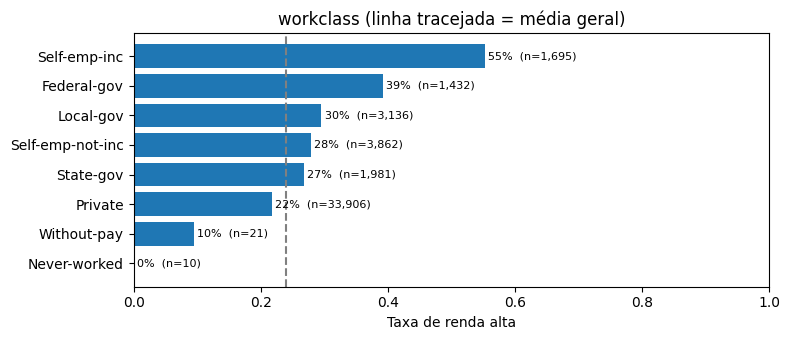

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.5))
taxa_por_categoria("workclass", ax=ax)
plt.tight_layout()
plt.show()

**Conclusão:** donos de empresa (`Self-emp-inc`, **55%**) e funcionários federais (39%) têm as maiores taxas; o setor privado, que concentra 70% das pessoas, fica um pouco abaixo da média (22%). As categorias `Without-pay` (21 pessoas) e `Never-worked` (10 pessoas, todas com renda baixa) são **raras demais** para conclusões firmes.

In [17]:
# native-country tem muitas categorias. Quantas, e como se distribuem?
paises = df["native-country"].value_counts()
print(f"Países diferentes: {paises.size}")
print(f"Estados Unidos: {paises.iloc[0] / paises.sum():.1%} das pessoas com país informado")
print(f"Países com menos de 50 pessoas: {(paises < 50).sum()}")
paises.head(8)

Países diferentes: 41
Estados Unidos: 91.3% das pessoas com país informado
Países com menos de 50 pessoas: 17


native-country
United-States    43832
Mexico             951
Philippines        295
Germany            206
Puerto-Rico        184
Canada             182
El-Salvador        155
India              151
Name: count, dtype: int64

**Conclusão:** há **41 países**, mas **91%** das pessoas são dos Estados Unidos, e **17 países** têm menos de 50 pessoas cada. Esse tipo de coluna, com **muitas categorias raras**, é um desafio: no notebook 03, ao transformar categorias em números, cada país viraria uma coluna nova, quase toda de zeros. Vamos discutir como lidar com isso (por exemplo, agrupando países raros em "Outros").

## 9. Colunas redundantes

In [18]:
# Cada nível de education corresponde a um único código education-num?
mapa = df.groupby("education", observed=True)["education-num"].agg(["min", "max", "nunique"])
print("Todos os níveis têm exatamente um código:", (mapa["nunique"] == 1).all())
mapa.sort_values("min").T

Todos os níveis têm exatamente um código: True


education,Preschool,1st-4th,5th-6th,7th-8th,9th,10th,11th,12th,HS-grad,Some-college,Assoc-voc,Assoc-acdm,Bachelors,Masters,Prof-school,Doctorate
min,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
max,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
nunique,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


In [19]:
# relationship × sex: a coluna de relacionamento já "sabe" o sexo?
pd.crosstab(df["relationship"], df["sex"])   # crosstab: tabela de contagem cruzando duas colunas

sex,Female,Male
relationship,,
Husband,1,19715
Not-in-family,5870,6713
Other-relative,689,817
Own-child,3376,4205
Unmarried,3928,1197
Wife,2328,3


**Conclusão:**
- **`education` e `education-num` são a mesma informação:** cada nível tem exatamente um código. Vamos usar só uma delas. A numérica é a melhor escolha, porque já carrega a **ordem** (doutorado > mestrado > graduação...).
- **`relationship` repete outras colunas:** `Husband` é praticamente sempre homem casado (19.715 de 19.716), e `Wife` é praticamente sempre mulher casada. Ela mistura informação de **estado civil** e de **sexo**.

Lembre da **multicolinearidade** do ML-01 (notebook 09): colunas que carregam a mesma informação deixam os coeficientes de modelos lineares instáveis. Para as árvores isso incomoda menos, mas é bom saber que essa redundância existe.

## 10. Correlação das numéricas com o alvo

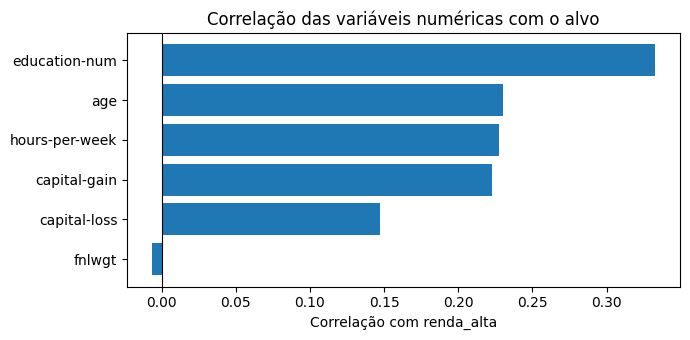

education-num     0.33
age               0.23
hours-per-week    0.23
capital-gain      0.22
capital-loss      0.15
fnlwgt           -0.01
Name: renda_alta, dtype: float64

In [20]:
# Como renda_alta é 0/1, a correlação com ela mostra quais números "andam junto" com a renda alta.
correlacao = df[numericas + ["renda_alta"]].corr()["renda_alta"].drop("renda_alta").sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(correlacao.index, correlacao.values)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlação com renda_alta")
ax.set_title("Correlação das variáveis numéricas com o alvo")
plt.tight_layout()
plt.show()

correlacao.sort_values(ascending=False).round(2)

**Conclusão:** a **escolaridade** tem a maior correlação (**0,33**), seguida de idade, horas trabalhadas e ganho de capital (todas ~0,22–0,23). Todas são positivas: mais de cada uma, mais chance de renda alta.

O **`fnlwgt` tem correlação de −0,01**, praticamente zero. Isso confirma o que vimos na seção 6: o peso amostral não descreve a pessoa e não ajuda a prever a renda. Vamos **descartá-lo** nos próximos notebooks.

⚠️ Lembre que a correlação só mede relações **lineares**. A idade, por exemplo, tem uma relação em "U" invertido (seção 7), mais forte do que 0,23 sugere.

## 11. Um primeiro olhar sobre justiça (fairness)

Vimos na seção 8 que homens têm quase 3 vezes mais renda alta que mulheres. Parte dessa diferença poderia ser explicada por outras características, como escolaridade ou horas trabalhadas. Vamos investigar.

In [21]:
print("Horas trabalhadas por semana (média):")
print(df.groupby("sex", observed=True)["hours-per-week"].mean().round(1).to_string())

# Comparando homens e mulheres com o MESMO nível de escolaridade:
# education-num >= 13 significa graduação (Bachelors) ou mais.
superior = np.where(df["education-num"] >= 13, "Com ensino superior", "Sem ensino superior")
print("\nTaxa de renda alta por sexo e escolaridade:")
# rownames dá um nome às linhas da tabela.
pd.crosstab(superior, df["sex"], values=df["renda_alta"], aggfunc="mean", rownames=["escolaridade"]).round(3)

Horas trabalhadas por semana (média):
sex
Female    36.4
Male      42.4

Taxa de renda alta por sexo e escolaridade:


sex,Female,Male
escolaridade,,
Com ensino superior,0.263,0.571
Sem ensino superior,0.066,0.209


**Conclusão:**
- Homens trabalham, em média, **6 horas a mais** por semana (42,4 contra 36,4), o que explica uma parte da diferença.
- Mas, **com o mesmo nível de escolaridade**, a diferença continua enorme: entre pessoas **com ensino superior**, **57%** dos homens ganham mais de 50 mil, contra **26%** das mulheres. Sem ensino superior: 21% contra 7%.

Esses dados registram uma **desigualdade real** de 1994. O ponto importante para ML é que **um modelo treinado com esses dados vai aprender e reproduzir essa desigualdade**. Se ele fosse usado, por exemplo, para aprovar crédito ou definir salários, poderia tratar mulheres de forma pior **só por serem mulheres**.

Não vamos simplesmente apagar a coluna `sex` e fingir que o problema sumiu: outras colunas, como `relationship` (seção 9), carregam a mesma informação "escondida". No notebook final vamos **medir** se o modelo erra mais para um grupo do que para outro. Esse é o tema da **justiça em Machine Learning** (*fairness*).

## 12. Resumo e próximos passos

**Achados principais**
- **48.842 pessoas**, com 6 colunas numéricas e 8 categóricas.
- **Alvo desbalanceado:** só **23,9%** ganham mais de 50 mil. Um "modelo" que sempre diz `<=50K` acerta 76% sem aprender nada.
- **Valores ausentes** em `workclass`, `occupation` e `native-country`. A ausência é **informativa** (9% de renda alta contra 25%).
- **Relações fortes com a renda:** escolaridade, estado civil, idade (em "U" invertido), profissão, horas e ganho de capital.
- **Colunas a descartar ou simplificar:** `fnlwgt` (peso amostral, correlação ≈ 0), `education` (redundante com `education-num`) e os países raros de `native-country`.
- **Fairness:** grandes diferenças por sexo e raça, que persistem mesmo com a mesma escolaridade.

**Conceitos que você aprendeu**
- Classificação × regressão; classes e classificação binária.
- Atributos numéricos × categóricos (ordinais e nominais).
- Classes desbalanceadas e a armadilha de "acertar 76%".
- Valores ausentes e quando a ausência carrega informação.
- Taxa da classe por categoria, e o cuidado com categorias raras.
- Colunas redundantes e uma primeira noção de fairness.

**Python novo:** `fetch_openml`, `select_dtypes`, `.tolist()`, `observed=True`, `pd.crosstab`, `np.where`, `.first()`, `pd.option_context` com `with`, `display()` e o operador `&` entre filtros.

**Próximo notebook (02):** o primeiro classificador. Vamos separar treino e teste (de forma **estratificada**), criar o baseline que "sempre chuta `<=50K`", treinar uma **regressão logística** e conhecer a **matriz de confusão**, a ferramenta que mostra **como** um classificador erra.